# Laboratório 5 – Regressão (gabarito) [<img src="https://raw.githubusercontent.com/urielmoreirasilva/ICX532/main/labs_gabs/Laborat%C3%B3rio%205%20%E2%80%93%20Regress%C3%A3o%20%28gabarito%29/images/colag_logo.svg" style="float: right; margin-right: 0%; vertical-align: middle; width: 6.5%;">](https://colab.research.google.com/github/urielmoreirasilva/ICX532/blob/main/labs_gabs/Laborat%C3%B3rio%205%20%E2%80%93%20Regress%C3%A3o%20%28gabarito%29/Laborat%C3%B3rio%205%20%E2%80%93%20Regress%C3%A3o%20%28gabarito%29.ipynb) [<img src="https://raw.githubusercontent.com/urielmoreirasilva/ICX532/main/labs_gabs/Laborat%C3%B3rio%205%20%E2%80%93%20Regress%C3%A3o%20%28gabarito%29/images/github_logo.svg" style="float: right; margin-right: 0%; vertical-align: middle; width: 3.25%;">](https://github.com/urielmoreirasilva/ICX532/blob/main/labs_gabs/Laborat%C3%B3rio%205%20%E2%80%93%20Regress%C3%A3o%20%28gabarito%29/Laborat%C3%B3rio%205%20%E2%80%93%20Regress%C3%A3o%20%28gabarito%29.ipynb)

Bem-vindo ao Laboratório 5, o último laboratório dessa disciplina! Neste laboratório, vamos praticar um pouco a técnica de regressão linear.

Você deve concluir todo este laboratório e enviá-lo ao Moodle até às 23h59 da data de vencimento.

### Referências
- [CIT: Capítulo 15](https://inferentialthinking.com/)
- Aulas: Tópico 18. 

Material adaptado do [DSC10 (UCSD)](https://dsc10.com/) por [Flavio Figueiredo (DCC-UFMG)](https://flaviovdf.io/fcd/) e [Uriel Silva (DEST-UFMG)](https://urielmoreirasilva.github.io)

In [1]:
## Imports para esse laboratório
import numpy as np
import pandas as pd

## Opções do MatplotLib 
import matplotlib.pyplot as plt
plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (10, 5)

## 1. Old Faithful

Old Faithful é um gêiser no Parque Nacional de Yellowstone, no centro dos Estados Unidos.  Ele é famoso por entrar em erupção com certa regularidade.

In [2]:
from IPython.display import YouTubeVideo

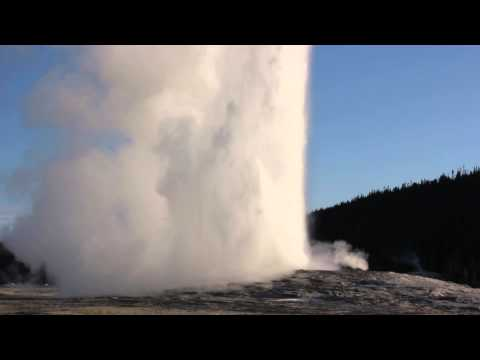

In [3]:
## Execute para ver o vídeo!
YouTubeVideo('wE8NDuzt8eg')

Algumas das erupções do Old Faithful duram mais do que outras.  Quando uma erupção mais longa ocorre, em geral também há uma espera mais longa até a próxima erupção.

Ao visitar Yellowstone, você pode querer prever quando a próxima erupção acontecerá, para que você possa ver o resto do parque e ir ver o gêiser quando ele estiver em erupção!  

Neste laboratório, utilizaremos um conjunto de dados sobre durações de erupções e tempos de espera para fazermos previsões através de regressão linear.

O conjunto de dados possui uma linha para cada erupção observada, e inclui as seguintes colunas:
- `'duration'`: Duração da erupção (em minutos);
- `'wait'`: Tempo entre a erupção atual e a próxima (em minutos).

In [4]:
faithful = pd.read_csv("https://raw.githubusercontent.com/urielmoreirasilva/ICX532/main/labs_gabs/Laborat%C3%B3rio%205%20%E2%80%93%20Regress%C3%A3o%20%28gabarito%29/data/faithful.csv")
faithful

,duration,wait
0,3.600,79.0
1,1.800,54.0
2,3.333,74.0
3,2.283,62.0
4,4.533,85.0
...,...,...
267,4.117,81.0
268,2.150,46.0
269,4.417,90.0
270,1.817,46.0


Antes de verificar se uma regressão linear é apropriada para modelar a associação entre as durações das erupções e os tempos de espera subsequente, é sempre uma boa ideia investigar se a relação entre essas variáveis é realmente linear!

#### **Pergunta 1.1.**

Faça um diagrama de dispersão dos dados em `faithful`.  Por convenção, tome `y` como nossa *variável dependente* (isto é, `wait`) e `x` como nossa *variável explicativa* (isto é, `duration`).

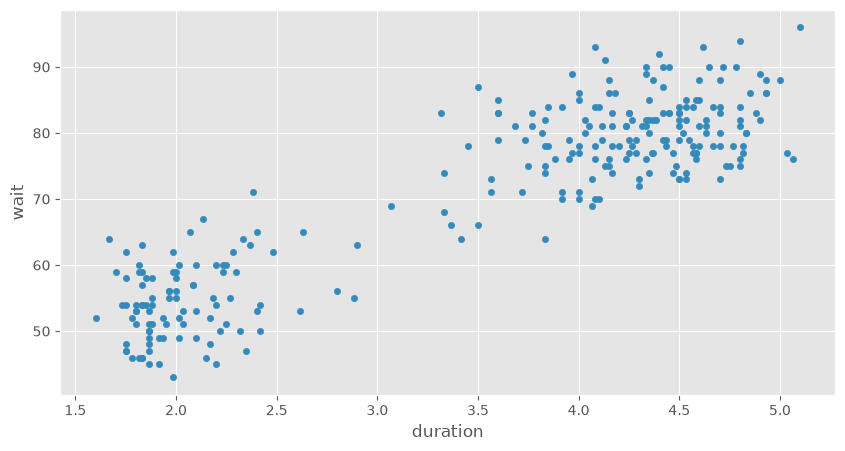

In [5]:
faithful.plot(kind = 'scatter', 
              y = 'wait', 
              x = 'duration',
              figsize = (10, 5));

#### **Pergunta 1.2.**

Sobre o diagrama de dispersão feito na Pergunta 1.1., escreva na célula de texto abaixo a alternativa **correta**.

**A.** A duração da erupção e o tempo de espera não parecem estar linearmente relacionados.

**B.** A duração da erupção e o tempo de espera estão aproximadamente linearmente relacionados, e a direção dessa associação é negativa.

**C.** A duração da erupção e o tempo de espera estão aproximadamente linearmente relacionados, e a direção dessa associação é positiva.

> **C**

Agora, gostaríamos de representar graficamente nossos dados sem influência de locação e escala, isto é, em unidades padronizadas.  

Lembre-se de que se `nums` for uma `Series` numérica, então

```py
    (nums - nums.mean()) / np.std(nums)
```

é uma versão padronizada de `nums`, isto é, uma `Series` contendo os elementos de `nums` expressos em unidades padronizadas.

#### **Pergunta 1.3.**

Calcule a média e o desvio padrão das durações das erupções e dos tempos de espera na célula de código abaixo utilizando as funções `np.mean` e `np.std`, respectivamente. Na célula de código seguinte, atribua então aos objetos `'duration_su'` e `'wait_su'` as versões padronizadas de `duration` e `wait`.

*<u>Nota</u>: Lembre que `su` vem do inglês <u>standard units</u>, e que literalmente quer dizer <u>unidades padronizadas</u>.*

In [6]:
duration_mean = np.mean(faithful.get("duration"))
duration_std = np.std(faithful.get("duration"))
wait_mean = np.mean(faithful.get("wait"))
wait_std = np.std(faithful.get("wait"))

In [7]:
duration_su = (faithful.get("duration") - duration_mean) / duration_std
wait_su = (faithful.get("wait") - wait_mean) / wait_std

#### **Pergunta 1.4.**

Crie na célula de código abaixo um DataFrame chamado `faithful_su`, cujas colunas `'duration_su'` e `'wait_su'` devem corresponder às `Series` que você criou na Pergunta 1.3.

In [8]:
faithful_su = pd.DataFrame().assign(
    duration_su = (faithful.get("duration") - duration_mean) / duration_std,
    wait_su = (faithful.get("wait") - wait_mean) / wait_std)
faithful_su

,duration_su,wait_su
0,0.098499,0.597123
1,-1.481459,-1.245181
2,-0.135861,0.228663
3,-1.057503,-0.655644
4,0.917443,1.039277
...,...,...
267,0.552298,0.744508
268,-1.174245,-1.834719
269,0.815624,1.407737
270,-1.466537,-1.834719


#### **Pergunta 1.5.**

Na célula de código abaixo, crie um gráfico de dispersão entre os tempos de espera e de duração das erupções (e logo análogo ao feito na Pergunta 1.1.), mas expressas em unidades padronizadas.

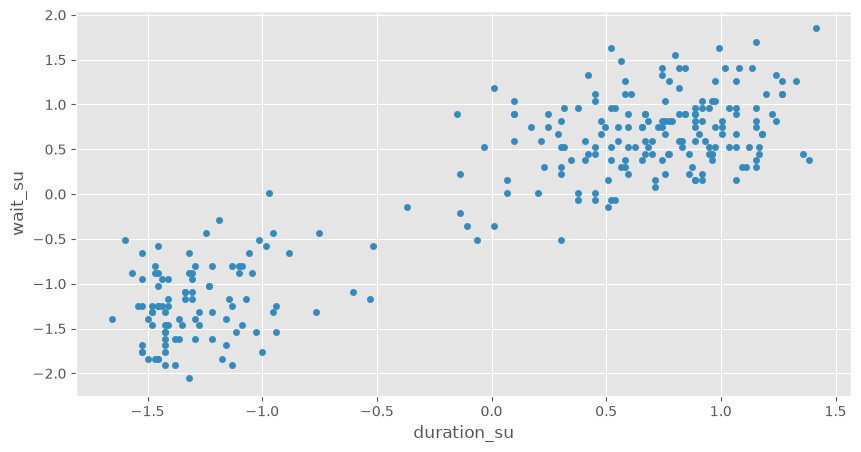

In [9]:
faithful_su.plot(kind = 'scatter', 
              y = 'wait_su', 
              x = 'duration_su',
              figsize = (10, 5));

Vamos calcular agora a correlação entre `duration` e `wait`.

Para fazermos isso, primeiro definimos uma função `standard_units`, que recebe um `array` ou `Series` de números e retorna uma cópia na qual todos os valores estão em unidades padronizadas.

In [10]:
def standard_units(any_numbers):
    '''Convert an array or Series of numbers to standard units.'''
    return (any_numbers - any_numbers.mean()) / np.std(any_numbers)

#### **Pergunta 1.6.**

Conclua a implementação da função `correlation` na célula de código abaixo. Essa função deve receber um DataFrame (`df`) e dois nomes de coluna (`x` e `y`) como argumentos, e retornar a correlação entre essas duas colunas. 

*<u>Dica</u>: Lembrando que o coeficiente de correlação entre duas variáveis pode ser calculada como a média do produto das colunas correspondentes (em unidades padronizadas), você pode utilizar as funções `standard_units` e `np.mean()` para calcular a correlação desejada em apenas uma linha de código.*

In [11]:
def correlation(df, x, y):
    return( np.mean(standard_units(df.get(x)) * standard_units(df.get(y))) )

#### **Pergunta 1.7.** 

Utilize a sua função `correlation` definida na Pergunta 1.6. para calcular a correlação entre duração e tempo de espera na célula de código abaixo. Atribua o resultado ao objeto `r` e verifique o resultado. Após fazer isso, comente na célula de texto seguinte se o valor encontrado é coerente com o padrão visual observado nos diagramas de dispersão elaborados nas Perguntas 1.1. e 1.5.

*<u>Dica</u>: O coeficiente de correlação `r` é invariante sob transformações lineares, o que aqui implica que a correlação entre `wait` e `duration` é a mesma do que a correlação entre `wait_su` e `duration_su`.*

In [12]:
r = correlation(faithful_su, "duration_su", "wait_su")
r

np.float64(0.900811168321813)

> ...

# 2. A reta de regressão

### A reta de regressão em unidades padronizadas

Primeiramente, é importante lembrar que a **reta de regressão em unidades padronizadas** é dada por

\begin{equation*}
    \widehat{\text{wait}}_{i \, (\text{su})} := r \cdot \text{duration}_{i \, (\text{su})}, 
\end{equation*}

isto é, uma reta com intercepto $\hat{a}_{(\text{su})} = 0$ e inclinação $\hat{b}_{(\text{su})} = r$.

Vamos agora visualizar a reta de regressão (em unidades padronizadas) nos nossos dados. Primeiramente, vamos definir na célula de código abaixo uma função para nos auxiliar nessa tarefa (por enquanto, não é necessário que você entenda os detalhes da implementação dessa função).

In [13]:
def plot_data_and_line(dataset, x, y, point_0, point_1):
    '''Makes a scatter plot of the dataset, along with a line passing through two points.'''
    dataset.plot(kind='scatter', x=x, y=y, label='data', figsize=(10, 5))
    xs, ys = zip(point_0, point_1)
    plt.plot(xs, ys, label='regression line', color='orange')
    plt.xlabel('duration')
    plt.ylabel('wait')
    plt.legend()

O próximo passo é então utilizar a função `plot_data_and_line` definida acima para criar um diagrama de dispersão onde a reta de regressão (em unidades padronizadas) é sobreposta aos nossos dados (também em unidades padronizadas):

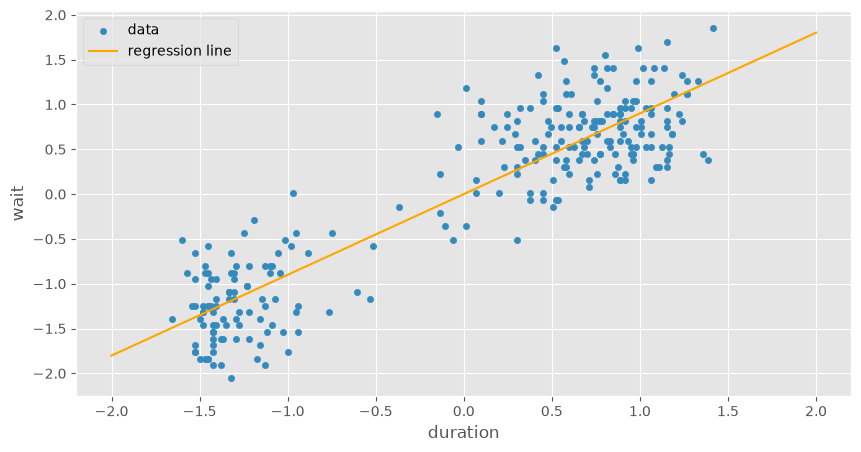

In [14]:
plot_data_and_line(faithful_su,
                   'duration_su',
                   'wait_su',
                   [-2, -2 * r],
                   [2, 2 * r])

### A reta de regressão no caso geral

No caso geral (isto é, nas unidades originais), a reta de regressão é dada por

\begin{equation*}
    \widehat{\text{wait}}_i := \hat{a} + \hat{b} \cdot \text{duration}_i, 
\end{equation*}

onde a inclinação é igual a

\begin{equation*}
    \hat{b} = r \cdot \frac{S_{\text{wait}}}{S_{\text{duration}}}
\end{equation*}

e o intercepto é igual a

\begin{equation*}
    \hat{a} = \overline{\text{duration}} - \hat{b} \cdot \overline{\text{wait}},
\end{equation*}

em que $\overline{\text{duration}}$ e $S_{\text{duration}}$ são, respectivamente, a média e o desvio padrão de `duration` e $\overline{\text{wait}}$ e $S_{\text{wait}}$ são, respectivamente, a média e o desvio padrão de `wait`.

#### **Pergunta 2.1.** 

Calcule na célula de código abaixo a inclinação $\hat{b}$ da reta de regressão de `wait` em `duration` em unidades originais. Atribua o resultado ao objeto `slope`.

*<u>Dica</u>: você pode utilizar o coeficiente de correlação `r` já calculado acima na Pergunta 1.7., e utilizar `np.std()` nas colunas correspondentes do DataFrame `faithful` para o cálculo dos desvios padrão.*

In [15]:
slope = r * np.std(faithful.get("wait")) / np.std(faithful.get("duration"))
slope

np.float64(10.729641395133525)

#### **Pergunta 2.2.** 

Calcule agora na célula de código abaixo o intercepto $\hat{a}$ da reta de regressão de `wait` em `duration` em unidades originais. Atribua o resultado ao objeto `intercept`.

*<u>Dica</u>: utilize o resultado da Pergunta 2.1., e utilize `np.mean()` nas colunas correspondentes do DataFrame `faithful` para o cálculo das médias.*

In [16]:
intercept = np.mean(faithful.get("wait")) - slope * np.mean(faithful.get("duration"))
intercept

np.float64(33.47439702275336)

# 3. Fazendo previsões com a reta de regressão

Utilizando uma notação um pouco mais geral, a reta de regressão é da forma

\begin{equation*}
    \hat{Y}_i := \hat{a} + \hat{b} \cdot X_i, 
\end{equation*}

onde $X_i$ é o tempo de duração da $i$-ésima erupção, e $\hat{Y}_i$ é o tempo de espera *predito* até a próxima erupção ($Y_i$ seria o tempo de espera *observado* correspondente), $i = 1, \ldots, n$.

Dessa forma, para qualquer tempo de duração $X_i$, a previsão do tempo de espera correspondente é feita simplesmente substituindo o valor apropriado na reta de regressão acima, isto é, multiplicando o valor $X_i$ pela inclinação $\hat{b}$ (`slope`) e somando esse valor ao intercepto $\hat{a}$ (`intercept`).

Apenas para fins de recordação, os valores da inclinação e intercepto da reta de regressão são, respectivamente:

In [17]:
slope

np.float64(10.729641395133525)

In [18]:
intercept

np.float64(33.47439702275336)

#### **Pergunta 3.1.**

Na célula de código abaixo, calcule os tempos de espera preditos para uma erupção que dura 2 minutos e para uma erupção que dura 5 minutos, respectivamente.

In [19]:
two_minute_predicted_waiting_time = intercept + slope * 2
five_minute_predicted_waiting_time = intercept + slope * 5

Abaixo definimos uma simples função para formatar melhor a saída das previsões feitas acima.

In [20]:
def print_prediction(duration, predicted_waiting_time):
    print('After an eruption lasting', duration,
          'minutes, we predict you\'ll wait', predicted_waiting_time,
          'minutes until the next eruption.')

Dessa forma:

In [21]:
print_prediction(2, two_minute_predicted_waiting_time)
print_prediction(5, five_minute_predicted_waiting_time)

After an eruption lasting 2 minutes, we predict you'll wait 54.933679813020404 minutes until the next eruption.
After an eruption lasting 5 minutes, we predict you'll wait 87.12260399842098 minutes until the next eruption.


A próxima célula traça a linha que vai entre esses dois pontos, que é (um segmento da) reta de regressão.

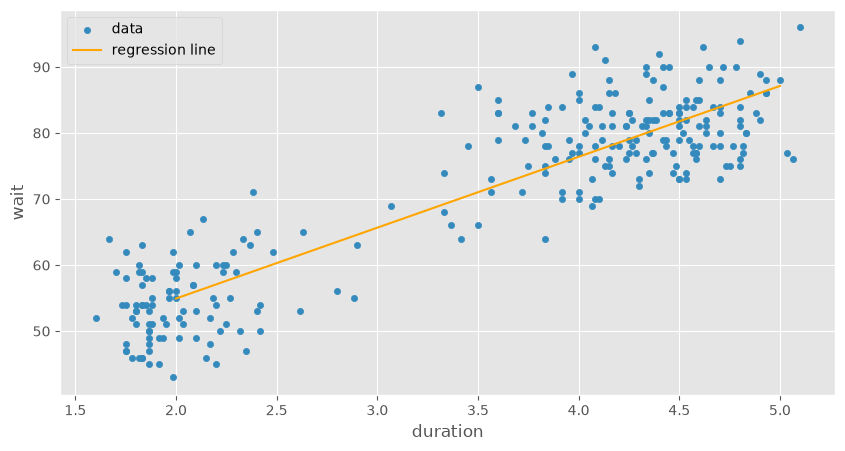

In [22]:
plot_data_and_line(faithful, 'duration', 'wait',
                   [2, two_minute_predicted_waiting_time],
                   [5, five_minute_predicted_waiting_time])

#### **Pergunta 3.2.** 

Na célula de código abaixo, faça previsões para o tempo de espera após *cada* erupção no DataFrame `faithful`. Seu resultado deverá ser uma `Series`, que você deve atribuir ao objeto `wait_predictions`.

*<u>Dica</u>: Você deve evitar a aplicação de `.apply()` ou de um loop `for` aqui – tente utilizar apenas operações ariméticas entre `Series`.*

In [23]:
wait_predictions = intercept + slope * faithful.get("duration")
wait_predictions

0      72.101106
1      52.787752
2      69.236292
3      57.970168
4      82.111861
         ...    
267    77.648331
268    56.543126
269    80.867223
270    52.970155
271    81.403705
Name: duration, Length: 272, dtype: float64

#### **Pergunta 3.3.**

Utilizando o resultado da Pergunta 3.2., crie na célula de código abaixo um novo DataFrame denominado `faithful_predictions`. Esse DataFrame deverá ser uma cópia de `faithful`, com uma coluna adicional, `'wait_predicted'`, cujo conteúdo devera ser igual às previsões dos tempos de espera em `wait_predictions`.

Para fins de comparação, a primeira linha de `faithful_predictions` deve ser assim:

||duration|wait|wait_predicted|
|-|-|-|-|
|**0**|3.600|79.0|72.101106|

In [24]:
faithful_predictions = faithful.assign(wait_predicted = wait_predictions)
faithful_predictions

,duration,wait,wait_predicted
0,3.600,79.0,72.101106
1,1.800,54.0,52.787752
2,3.333,74.0,69.236292
3,2.283,62.0,57.970168
4,4.533,85.0,82.111861
...,...,...,...
267,4.117,81.0,77.648331
268,2.150,46.0,56.543126
269,4.417,90.0,80.867223
270,1.817,46.0,52.970155


### Diagnósticos em um modelo de regressão

Uma quantidade muito importante para diagnosticar modelos de regressão são os **resíduos**, definidos por

\begin{equation*}
    \hat{\varepsilon}_i := Y_i - \hat{Y}_i,
\end{equation*}

onde $Y_i$ denota o valor **observado** da $i$-ésima observação da nossa variável dependente e $\hat{Y}_i$ o valor **predito** correspondente, $i = 1, \ldots, n$.

Essencialmente, se um modelo de regressão estiver bem ajustado aos nossos dados, os resíduos terão um comportamento de *erro aleatório*, isto é, serão distribuídos aleatoriamente em torno de sua média (que podemos provar matematicamente ser igual a $0$). 

Além disso, é importante que nos resíduos não haja nenhuma observação discrepante/extrema/*outlier*. Lembre-se das nossas aulas que esse tipo de observação pode levar à um *viés* nas nossas estimativas!

#### **Pergunta 3.4.** 

Na célula de código abaixo, calcule o resíduo correspondente à cada observação do nosso banco de dados, e atribua esses resíduos ao objeto `residuals`. Depois disso, crie um novo DataFrame, que deve ser denominado `faithful_residuals` e que deverá ser uma cópia de `faithful_predictions` com uma coluna adicional, `'residual'`, cujo conteúdo devera ser o mesmo de `residuals`.

*<u>Dica</u>: Mais uma vez você deve evitar a aplicação de `.apply()` ou de um loop `for` aqui – tente utilizar apenas operações ariméticas entre `Series`.*

In [25]:
residuals = faithful_predictions.get('wait') - faithful_predictions.get('wait_predicted')
faithful_residuals = faithful_predictions.assign(residual = residuals)
faithful_residuals

,duration,wait,wait_predicted,residual
0,3.600,79.0,72.101106,6.898894
1,1.800,54.0,52.787752,1.212248
2,3.333,74.0,69.236292,4.763708
3,2.283,62.0,57.970168,4.029832
4,4.533,85.0,82.111861,2.888139
...,...,...,...,...
267,4.117,81.0,77.648331,3.351669
268,2.150,46.0,56.543126,-10.543126
269,4.417,90.0,80.867223,9.132777
270,1.817,46.0,52.970155,-6.970155


#### **Pergunta 3.5.**

Elabore na célula de código abaixo um diagrama de dispersão dos resíduos calculados na Pergunta 3.4. contra o índice das observações de `faithful_residuals` (isto é, de `0` a `271`). 

Se você fez tudo certo até agora, você deverá ver que os resíduos aqui exibem o padrão "ideal" descrito acima, isto é, um padrão aleatório em torno de sua média 0, e sem observações discrepantes/extremas/*outliers*.

*<u>Dica</u>: Você pode elaborar um diagrama de dispersão com apenas uma coluna `y` tomando `style = '.'` após chamar o método `.plot()` no `DataFrame` correspondente. *

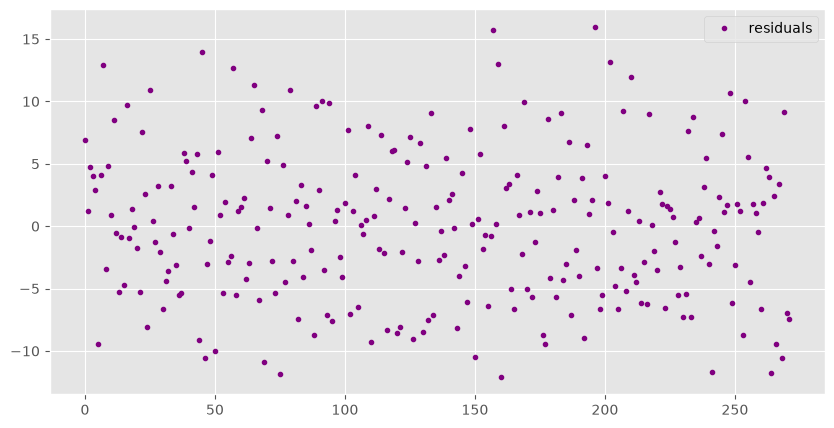

In [26]:
faithful_residuals.plot(
    style = '.',
    y = 'residual',
    label = 'residuals',
    color = 'purple',
    figsize = (10, 5));

# 4. E quão precisas são as nossas previsões?

Nas análises acima, você deve ter descoberto que a correlação entre `duration` e `wait` é bem alta (próxima de 1), o que sugere uma relação linear entre nossos dados, e naturalmente um bom ajuste de um modelo de regressão linear.

No entanto, mesmo que a reta de regressão se ajuste bem aos dados, devemos sempre ter cuidado ao fazer previsões em dados que sejam muito diferentes dos dados da sua amostra.

#### **Pergunta 4.1.** 

No nosso DataFrame `faithful`, nenhuma erupção durou exatamente 0, 2.5 ou 60 minutos. Na célula de código abaixo, utilize então a reta de regressão para prever o tempo de espera pela próxima erupção depois de uma erupção durando, respectivamente, 0 minutos,  2.5 minutos e  60 minutos (uma hora). Comente na célula de texto que se segue sobre quais previsões você acha que são razoáveis, e explique brevemente seu raciocínio.

*<u>Dica</u> Para ajudar a fundamentar sua explicação, pode ajudar saber que, em `faithful`, o mínimo, máximo e média da coluna `'duration'` são, respectivamente, 1.60, 3.49 e 5.10 minutos.*

In [27]:
zero_minute_predicted_waiting_time = intercept + slope * 0
two_point_five_minute_predicted_waiting_time = intercept + slope * 2.50
hour_predicted_waiting_time = intercept + slope * 60

print_prediction(0, zero_minute_predicted_waiting_time)
print_prediction(2.5, two_point_five_minute_predicted_waiting_time)
print_prediction(60, hour_predicted_waiting_time)

After an eruption lasting 0 minutes, we predict you'll wait 33.47439702275336 minutes until the next eruption.
After an eruption lasting 2.5 minutes, we predict you'll wait 60.298500510587175 minutes until the next eruption.
After an eruption lasting 60 minutes, we predict you'll wait 677.2528807307649 minutes until the next eruption.


> A previsão para 2.5 minutos parece bem razoável, pois esse é um valor "típico" no nosso banco de dados. A previsão para 0 minutos é pouco razoável, pois essa previsão é essencialmente o intercepto da reta de regressão, e uma erupção que dura 0 minutos não faz sentido na prática. Analogamente, uma duração de 60 minutos (ou 1 hora) é muito maior do que qualquer coisa que já foi observada no nosso conjunto de dados (um valor bem atípico), e a espera predita provavelmente também não seria confiável nesse caso.

### Coeficiente de determinação

Uma maneira mais formal de aferirmos a qualidade do ajuste de um modelo de regressão aos nossos dados é através do **coeficiente de determinação**, usualmente denotado como $R^2$. 

Em termos simples, o $R^2$ mede o "percentual da variabilidade da variável resposta/dependente ($Y_i$, aqui dado por `'wait'`) explicado pela variável explicativa/preditora ($X_i$, aqui dada por `'duration'`)".

Uma maneira simples de calcular o $R^2$ em um modelo de regressão é através do *quadrado da correlação entre os valores reais/observados $Y_i$ e as predições $\hat{Y}_i$*, isto é,

\begin{equation*}
    R^2 = \text{corr}(Y_i, \hat{Y}_i)^2
\end{equation*}

#### **Pergunta 4.2.**

Na célula de código abaixo, calcule o coeficiente de determinação do nosso modelo de regressão, e atribua o resultado ao objeto R2. Lembre-se que ambas as variáveis resposta observadas e preditas estão disponíveis em `faithful_residuals`.

*<u>Dica</u> Utilize a função `correlation` definida na Pergunta 1.6., e não se esqueça de elevar o resultado ao quadrado!.*

In [28]:
R2 = correlation(faithful_residuals, 'wait', 'wait_predicted')
R2

np.float64(0.9008111683218132)

# 5. Dividir e conquistar

Se voltarmos ao início da nossa análise exploratória e inspecionarmos novamente o diagrama de dispersão entre `duration` e `wait`, podemos ver que aparentemente existem dois grupos de observações: um cujas durações têm em torno de 2 minutos, e outro, cujas durações têm entre 3.5 e 5 minutos. Uma linha vertical em 3 minutos divide os dois grupos.

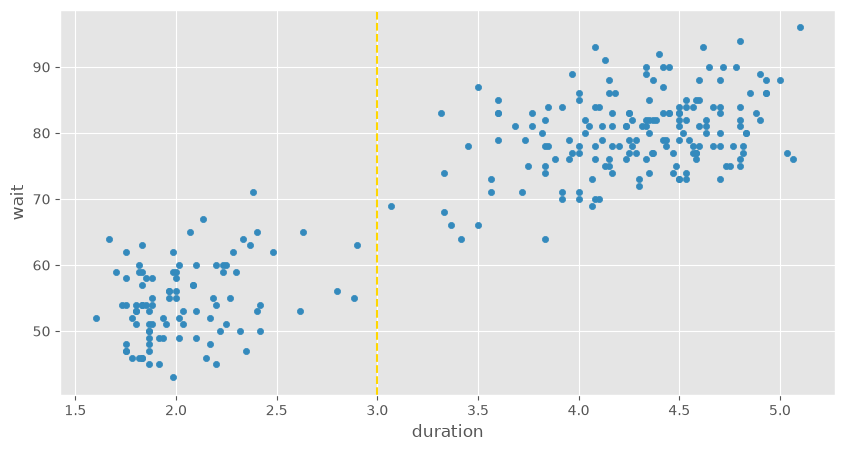

In [29]:
faithful_residuals.plot(
    kind = 'scatter', 
    x = 'duration', 
    y = 'wait', 
    figsize = (10, 5))
plt.axvline(x = 3, color = 'gold', linestyle = 'dashed');

Sob uma perspectiva diferente, podemos chegar à mesma conclusão ao analisar o diagrama de dispersão entre os resíduos (no eixo `y`) e os tempos de duração (no eixo `x`). Esse tipo de gráfico é também muito útil para detectarmos padrões nos nossos dados que não foram capturados pelo modelo de regressão.

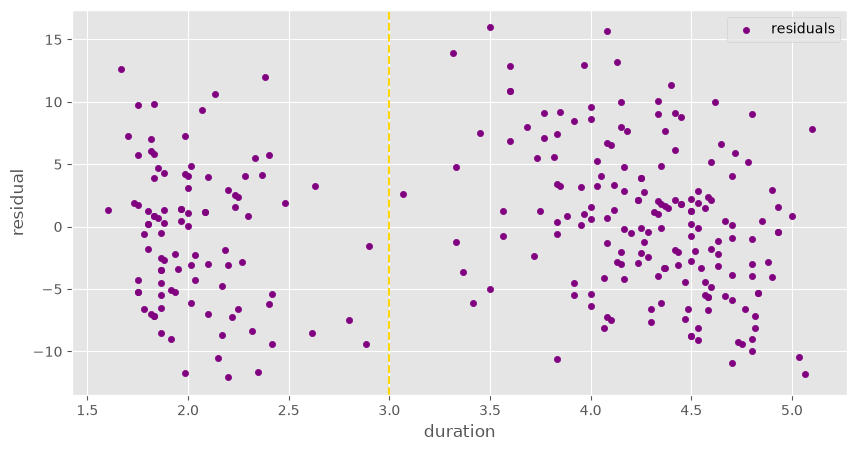

In [30]:
faithful_residuals.plot(
    kind = 'scatter',
    x = 'duration',
    y = 'residual',
    label = 'residuals',
    color = 'purple',
    figsize=(10, 5));
plt.axvline(x = 3, color = 'gold', linestyle = 'dashed');

#### **Pergunta 5.1.** 

Atribua `below_3_r` ao coeficiente de correlação de todos os pontos com duração inferior a 3 e `above_3_r` ao coeficiente de correlação de todos os pontos com duração maior ou igual a 3. Para isso:
1. Crie dois DataFrames, `below_3` e `above_3`. `below_3` deve conter todas as linhas em `faithful` em que a duração é inferior a 3, e `above_3` deve conter todas as linhas em `faithful` em que a duração é maior ou igual a 3.
2. Chame sua função `correlation` da Questão 1.6 em `below_3` e `above_3`.

In [31]:
below_3 = faithful[faithful.get('duration') < 3]
above_3 = faithful[faithful.get('duration') >= 3]

below_3_r = correlation(below_3, "duration", "wait")
above_3_r = correlation(above_3, "duration", "wait")
print(f'For points below 3, r is {below_3_r}. \nFor points above 3, r is {above_3_r}.')

For points below 3, r is 0.2901895264925431. 
For points above 3, r is 0.3727822255707511.


#### **Pergunta 5.2.** 

Abaixo, complete a implementação das funções `slope_of` e `intercept_of`. Ambas as funções devem receber um DataFrame `df` que contém uma coluna `'duration'` e uma coluna `'wait'` (ambas em **unidades originais**, não em unidades padrão).

Quando terminar, as funções `wait_below_3` e `wait_above_3` devem usar, cada uma, uma linha de regressão diferente para prever um tempo de espera por uma duração. A primeira função deve usar a linha de regressão para todos os pontos com duração **abaixo** de 3. A segunda função deve usar a linha de regressão para todos os pontos com duração **maior ou igual a** 3.

In [32]:
def slope_of(df):
    '''Retorne a inclinação da linha de regressão para o DataFrame fornecido nas unidades originais.
    Assuma que a coluna duration contém os valores de x e a coluna wait contém os valores de y.
    '''
    slope = correlation(df, "duration", "wait") * np.std(df.get("wait")) / np.std(df.get("duration"))
    return(slope)

def intercept_of(df):
    '''Retorne a inclinação da linha de regressão para o DataFrame fornecido nas unidades originais.
    Assuma que a coluna duration contém os valores de x e a coluna wait contém os valores de y.
    '''
    intercept = np.mean(df.get("wait")) - slope_of(df) * np.mean(df.get("duration"))
    return(intercept)
    
below_3_a = slope_of(below_3)
below_3_b = intercept_of(below_3)
above_3_a = slope_of(above_3)
above_3_b = intercept_of(above_3)

def wait_below_3(duration):
    return below_3_a * duration + below_3_b

def wait_above_3(duration):
    return above_3_a * duration + above_3_b

O gráfico abaixo mostra duas linhas de regressão diferentes, uma para cada grupo!

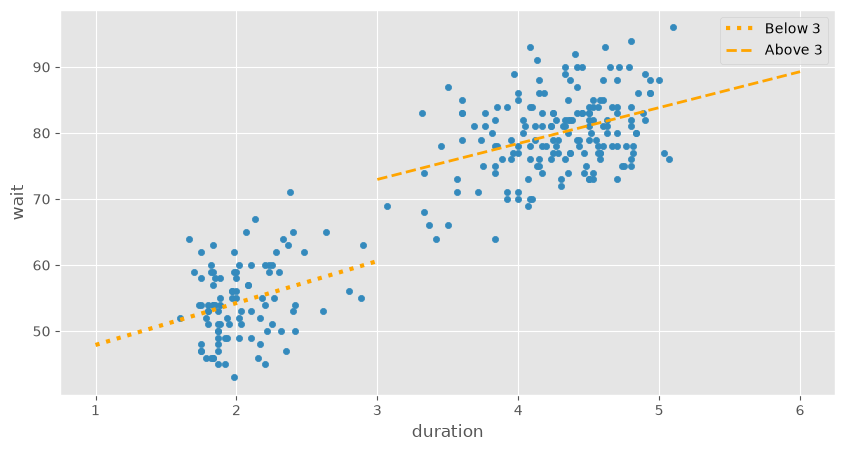

In [33]:
faithful_residuals.plot(kind = 'scatter', x = 'duration', y = 'wait', figsize = (10, 5))
plt.plot([1, 3], [wait_below_3(1), wait_below_3(3)], ':', color = 'orange', label = 'Below 3', linewidth = 3)
plt.plot([3, 6], [wait_above_3(3), wait_above_3(6)], '--', color = 'orange', label = 'Above 3', linewidth = 2)
plt.legend();

#### **Pergunta 5.3.** 

Escreva uma função `predict_wait` que receba uma `duration` e retorne o tempo de espera previsto usando a linha de regressão apropriada, dependendo se a duração é inferior a 3 ou maior ou igual a 3.

In [34]:
def predict_wait(duration):
    '''Retorne a espera prevista pela linha de regressão apropriada dentre as duas mencionadas acima.'''
    if(duration < 3):
        return(wait_below_3(duration))
    if(duration >= 3):
        return(wait_above_3(duration))

Os tempos de espera previstos para cada ponto aparecem abaixo.

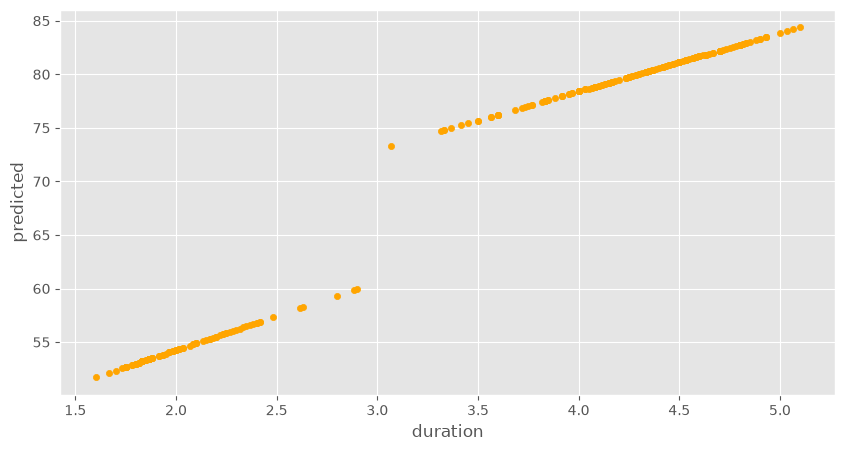

In [35]:
new_faithful = faithful.assign(predicted = faithful.get('duration').apply(predict_wait))
new_faithful.plot(kind = 'scatter', x = 'duration', y = 'predicted', color = 'orange', figsize = (10, 5));

Como podemos ver na figura acima, as previsões do nosso modelo agora são feitas de maneira diferente para cada grupo, de acordo com a reta de regressão correspondente. 

Formalmente, essa abordagem consiste no que é chamada como *regressão local*, em que cada grupo (ou segmento) de observações têm sua própria reta de regressão.

Finalmente, vamos verificar se a abordagem acima realmente produz resultados melhores do que o nosso modelo original (isto é, sem *estratificarmos* a amostra entre grupos).

Para realizar a comparação entre ambos os modelos, vamos utilizar novamente o coeficiente de determinação $R^2$ definido acima. Lembre da Pergunta 4.2. que o $R^2$ para o modelo de regressão original era igual a:

In [36]:
R2

np.float64(0.9008111683218132)

#### **Pergunta 5.4.** 

Na célula de código abaixo, calcule o coeficiente de determinação $R^2$ do novo modelo de regressão, cuja coluna de valores preditos (`predicted`) se encontra no DataFrame `new_faithful`. Atribua o valor desse novo $R^2$ ao objeto `new_R2` e, na célula de texto abaixo, compare brevemente sobre os valores de `R2` e `new_R2`, e comente se a elaboração de um novo modelo é realmente justificável através dessa métrica. 

In [37]:
new_R2 = correlation(new_faithful, 'wait', 'predicted') ** 2
new_R2

np.float64(0.8326578812946601)

> Um aumento no coeficiente de determinação *pode*, em muitas situações, justificar um modelo mais complexo. Porém, no nosso caso, `new_R2` é *menor* que `R2`, e como então o modelo com melhor ajuste aos dados (com apenas um grupo) também é o mais simples/*parcimonioso*, não há razão para escolhermos o modelo mais complexo (com os 2 grupos).   

# Linha de chegada 🏁

Parabéns! Você concluiu o Laboratório 5 com sucesso 👏👏👏

Para enviar sua tarefa:

1. Selecione `Kernel -> Restart Kernel and Run All Cells` para garantir que você executou todas as células, incluindo as células de teste.
1. Leia o notebook do começo ao fim com cuidado para ter certeza de que está tudo bem e que todos os testes foram aprovados.
1. Baixe seu notebook usando `File -> Save and Export Notebook As -> HTML` e, em seguida, carregue seu notebook para o Moodle.